# Forest Cover Type Classification
**Elevvo Machine Learning Internship, Level 2: multi-class classification with tree-based models**

**Goal:** predict the type of forest cover (7 classes) of a 30 m x 30 m land cell from cartographic and environmental features, and compare tree-based models (Random Forest vs XGBoost) with hyperparameter tuning.

## Dataset properties (UCI Covertype)

| Property | Value |
|---|---|
| Rows x columns | 581,012 x 54 features + 1 target |
| Area | Roosevelt National Forest, Colorado (four wilderness areas) |
| Continuous features (10) | elevation, aspect, slope, distances to hydrology / roadways / fire points, vertical distance to hydrology, three hillshade indices |
| Binary features (44) | 4 `wilderness_area` indicators and 40 `soil_type` indicators, both **one-hot encoded** |
| Target | `Cover_Type`, 7 classes (Spruce/Fir, Lodgepole Pine, Ponderosa Pine, Cottonwood/Willow, Aspen, Douglas-fir, Krummholz) |
| Class balance | heavily skewed: the two largest classes cover about 85% of the data and the smallest is under 1% (exact counts are printed in Section 2) |

**Engineering decisions driven by these properties**
- **Multi-class + imbalance:** the headline metric is **macro-F1** (every class counts equally) next to accuracy, with per-class precision/recall and a normalised confusion matrix. A majority-class dummy is the reality check.
- **Categorical handling:** the one-hot structure is *validated* (exactly one wilderness area and one soil type per row), decoded into readable categorical columns for EDA, and kept as binary indicators for modelling. Trees split on indicators natively, and an ordinal soil-type code would invent an order that does not exist.
- **Size (about 0.58 M rows):** a single stratified validation split replaces 5-fold CV for model comparison, and hyperparameter search runs on a subsample, then the winner is refitted on all training data.
- **Axis-aligned trees:** like the `loan_to_income` lesson in the previous task, trees approximate combinations of columns poorly, so **engineered combination features** are tested in an ablation.
- **Spatial data:** neighbouring cells are similar, so a random split is optimistic. Section 10 quantifies this with a leave-one-wilderness-area-out test.

## Task requirements and where they are covered

| Requirement | Section |
|---|---|
| Clean and preprocess, including categorical handling | 1, 3 |
| Train and evaluate multi-class models | 5, 7 |
| Visualise confusion matrix and feature importance | 7, 8 |
| Bonus: compare Random Forest vs XGBoost | 5 |
| Bonus: hyperparameter tuning | 6 |

## Plan
0. Configuration | 1. Load, validate, clean | 2. EDA | 3. Feature engineering and splits | 4. Engineered-feature ablation | 5. Model comparison | 6. Tuning | 7. Final test evaluation | 8. Feature importance | 9. Learning curve | 10. Spatial stress test | 11. Save | 12. Conclusions

**How to run:** first set `FAST_MODE = True` for a quick dry run on a 60k-row subsample (a few minutes). Then set it to `False` and use *Restart and Run All* for the real results. Expect this to take a long time on a laptop (my rough guess is one to two hours): the hyperparameter search and the refits of the tuned forests on all training rows dominate, so start it when you can leave it running. Figures go to `images/`, tables to `results/`, the model to `models/`.

In [1]:
import time
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support)

try:
    from xgboost import XGBClassifier
except ImportError:
    %pip install xgboost
    from xgboost import XGBClassifier
import xgboost

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

pandas 3.0.3 | scikit-learn 1.9.0 | xgboost 3.4.1


## 0. Configuration

In [2]:
RANDOM_STATE = 42
FAST_MODE = False          # True = dry run on a small subsample (few minutes); False = full run
FAST_N = 60_000            # rows kept in FAST_MODE
DATA_SOURCE = "sklearn"    # "sklearn" downloads via fetch_covtype (needs internet, cached afterwards)
                           # or a path to the UCI file covtype.data / covtype.data.gz
N_JOBS = -1
SAVE_MODEL = True         # a tuned Random Forest can exceed 1 GB on disk: set False to skip saving

# Compute budgets (automatically reduced in FAST_MODE)
RF_TREES   = 40 if FAST_MODE else 100      # trees in the comparison forests
XGB_ROUNDS = 100 if FAST_MODE else 300     # boosting rounds in the comparison XGBoost
ABL_N      = 30_000 if FAST_MODE else 100_000   # rows for the feature ablation
LR_N       = 20_000 if FAST_MODE else 100_000   # rows for the logistic regression baseline
TUNE_N     = 20_000 if FAST_MODE else 50_000    # rows used inside the hyperparameter search
N_ITER     = 3 if FAST_MODE else 6              # random-search candidates per model
SPATIAL_N  = 20_000 if FAST_MODE else 100_000   # rows for the leave-one-area-out test
PERM_N     = 10_000 if FAST_MODE else 30_000    # rows for permutation importance

IMG_DIR = Path("images");  IMG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

def save_fig(name):
    plt.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

CLASS_NAMES = ["Spruce/Fir", "Lodgepole Pine", "Ponderosa Pine", "Cottonwood/Willow", "Aspen", "Douglas-fir", "Krummholz"]
SHORT_NAMES = ["Spruce/Fir", "Lodgepole", "Ponderosa", "Cottonwood", "Aspen", "Douglas-fir", "Krummholz"]
AREA_NAMES = {1: "Rawah", 2: "Neota", 3: "Comanche Peak", 4: "Cache la Poudre"}

NUM_COLS = ["elevation", "aspect", "slope", "horizontal_distance_to_hydrology",
            "vertical_distance_to_hydrology", "horizontal_distance_to_roadways",
            "hillshade_9am", "hillshade_noon", "hillshade_3pm", "horizontal_distance_to_fire_points"]

## 1. Load, validate and clean

Steps: load, normalise column names, assert the schema, shrink memory (float32 / int8), then **validate the one-hot structure** and decode it for EDA. Constant columns are detected and dropped, and value ranges are checked against the dataset documentation.

In [3]:
def load_covtype(source):
    if source == "sklearn":
        try:
            bunch = fetch_covtype(as_frame=True)
        except Exception as e:
            raise RuntimeError("Could not download Covertype via scikit-learn (internet needed). "
                               "Download covtype.data.gz from the UCI repository and set DATA_SOURCE to its path.") from e
        Xr, yr = bunch.data.copy(), bunch.target.copy()
    else:
        raw = pd.read_csv(source, header=None)
        assert raw.shape[1] == 55, f"Expected 55 columns (54 features + target), found {raw.shape[1]}"
        Xr, yr = raw.iloc[:, :54].copy(), raw.iloc[:, 54].copy()
        Xr.columns = (NUM_COLS + [f"wilderness_area_{i}" for i in range(4)]
                      + [f"soil_type_{i}" for i in range(40)])
    Xr.columns = [c.strip().lower() for c in Xr.columns]
    return Xr, yr

def suffix(c):
    return int(c.rsplit("_", 1)[1])

Xr, yr = load_covtype(DATA_SOURCE)

WILD_COLS = sorted([c for c in Xr.columns if c.startswith("wilderness_area")], key=suffix)
SOIL_COLS = sorted([c for c in Xr.columns if c.startswith("soil_type")], key=suffix)
assert set(NUM_COLS) <= set(Xr.columns), f"Missing numeric columns: {set(NUM_COLS) - set(Xr.columns)}"
assert len(WILD_COLS) == 4 and len(SOIL_COLS) == 40, (len(WILD_COLS), len(SOIL_COLS))

y_raw = yr.astype(int)
assert set(y_raw.unique()) == set(range(1, 8)), f"Unexpected labels: {sorted(y_raw.unique())}"

if FAST_MODE:
    Xr, _, y_raw, _ = train_test_split(Xr, y_raw, train_size=FAST_N, stratify=y_raw, random_state=RANDOM_STATE)
    Xr, y_raw = Xr.reset_index(drop=True), y_raw.reset_index(drop=True)
    print(f"FAST_MODE: using a stratified subsample of {len(Xr):,} rows")

X = Xr[NUM_COLS + WILD_COLS + SOIL_COLS].astype(
    {**{c: "float32" for c in NUM_COLS}, **{c: "int8" for c in WILD_COLS + SOIL_COLS}})
y = (y_raw - 1).astype("int8")          # classes 0..6 (XGBoost needs consecutive labels from 0)

print("Shape:", X.shape, "| memory:", round(X.memory_usage(deep=True).sum() / 1e6), "MB")

Shape: (581012, 54) | memory: 49 MB


In [4]:
# ---- One-hot integrity: exactly one wilderness area and one soil type per row? ----
print("Rows with exactly one wilderness area:", int((X[WILD_COLS].sum(axis=1) == 1).sum()), "of", len(X))
print("Rows with exactly one soil type      :", int((X[SOIL_COLS].sum(axis=1) == 1).sum()), "of", len(X))

# ---- Decode to readable categorical columns (used for EDA only) ----
area = pd.Series(X[WILD_COLS].to_numpy().argmax(axis=1) + 1, index=X.index, name="wilderness_area")
soil = pd.Series(X[SOIL_COLS].to_numpy().argmax(axis=1) + 1, index=X.index, name="soil_type")

# ---- Constant / near-constant columns ----
const_cols = [c for c in X.columns if X[c].nunique() <= 1]
rare_soil = {c: int(X[c].sum()) for c in SOIL_COLS if 0 < X[c].sum() < 50}
print("\nConstant columns (dropped):", const_cols if const_cols else "none")
print("Very rare soil types (<50 rows):", rare_soil if rare_soil else "none")
X = X.drop(columns=const_cols)
SOIL_COLS = [c for c in SOIL_COLS if c not in const_cols]
WILD_COLS = [c for c in WILD_COLS if c not in const_cols]

# ---- Data-quality checks ----
print("\nMissing values       :", int(X.isna().sum().sum()))
print("Duplicate rows       :", int(X.duplicated().sum()))
print("Hillshade outside 0-255:", int(((X[["hillshade_9am", "hillshade_noon", "hillshade_3pm"]] < 0) |
                                       (X[["hillshade_9am", "hillshade_noon", "hillshade_3pm"]] > 255)).any(axis=1).sum()))
print("Aspect outside 0-360 :", int(((X["aspect"] < 0) | (X["aspect"] > 360)).sum()))
print("Slope outside 0-90   :", int(((X["slope"] < 0) | (X["slope"] > 90)).sum()))
print("Negative vertical distance to hydrology:", int((X["vertical_distance_to_hydrology"] < 0).sum()),
      "(valid: the water source lies above the cell)")
X[NUM_COLS].describe().round(1)

Rows with exactly one wilderness area: 581012 of 581012
Rows with exactly one soil type      : 581012 of 581012

Constant columns (dropped): none
Very rare soil types (<50 rows): {'soil_type_14': 3}

Missing values       : 0
Duplicate rows       : 0
Hillshade outside 0-255: 0
Aspect outside 0-360 : 0
Slope outside 0-90   : 0
Negative vertical distance to hydrology: 55143 (valid: the water source lies above the cell)


,elevation,aspect,slope,horizontal_distance_to_hydrology,vertical_distance_to_hydrology,horizontal_distance_to_roadways,hillshade_9am,hillshade_noon,hillshade_3pm,horizontal_distance_to_fire_points
count,581012.0,581012.0,581012.0,581012.0,581012.0,581012.0,581012.0,581012.0,581012.0,581012.0
mean,2959.4,155.7,14.1,269.4,46.4,2350.1,212.1,223.3,142.5,1980.3
std,280.0,111.9,7.5,212.5,58.3,1559.3,26.8,19.8,38.3,1324.2
min,1859.0,0.0,0.0,0.0,-173.0,0.0,0.0,0.0,0.0,0.0
25%,2809.0,58.0,9.0,108.0,7.0,1106.0,198.0,213.0,119.0,1024.0
50%,2996.0,127.0,13.0,218.0,30.0,1997.0,218.0,226.0,143.0,1710.0
75%,3163.0,260.0,18.0,384.0,69.0,3328.0,231.0,237.0,168.0,2550.0
max,3858.0,360.0,66.0,1397.0,601.0,7117.0,254.0,254.0,254.0,7173.0


## 2. Exploratory data analysis

Questions to answer:
- How imbalanced are the seven classes, and what accuracy does always predicting the majority class get?
- Which features separate the classes? (Elevation is expected to dominate.)
- How do wilderness areas and soil types relate to the cover types? Are some classes confined to one area?
- Are the continuous features correlated with each other?

               class    rows   share
1         Spruce/Fir  211840  0.3646
2     Lodgepole Pine  283301  0.4876
3     Ponderosa Pine   35754  0.0615
4  Cottonwood/Willow    2747  0.0047
5              Aspen    9493  0.0163
6        Douglas-fir   17367  0.0299
7          Krummholz   20510  0.0353

Accuracy of always predicting the majority class: 0.488
Smallest class: Cottonwood/Willow (2,747 rows, 0.47%)


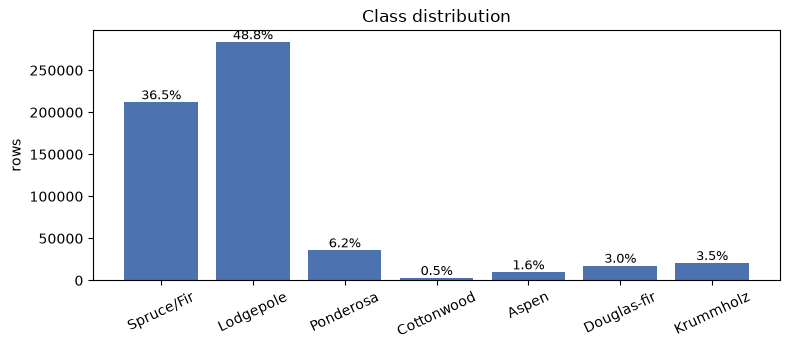

In [5]:
counts = y.value_counts().sort_index()
dist = pd.DataFrame({"class": CLASS_NAMES, "rows": counts.values, "share": (counts.values / len(y)).round(4)},
                    index=range(1, 8))
print(dist.to_string())
print(f"\nAccuracy of always predicting the majority class: {counts.max() / len(y):.3f}")
print(f"Smallest class: {CLASS_NAMES[int(counts.idxmin())]} ({counts.min():,} rows, {counts.min() / len(y):.2%})")

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(SHORT_NAMES, counts.values, color="#4C72B0")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v / len(y):.1%}", ha="center", va="bottom", fontsize=9)
ax.set_title("Class distribution"); ax.set_ylabel("rows"); plt.xticks(rotation=25)
plt.tight_layout(); save_fig("eda_class_distribution"); plt.show()

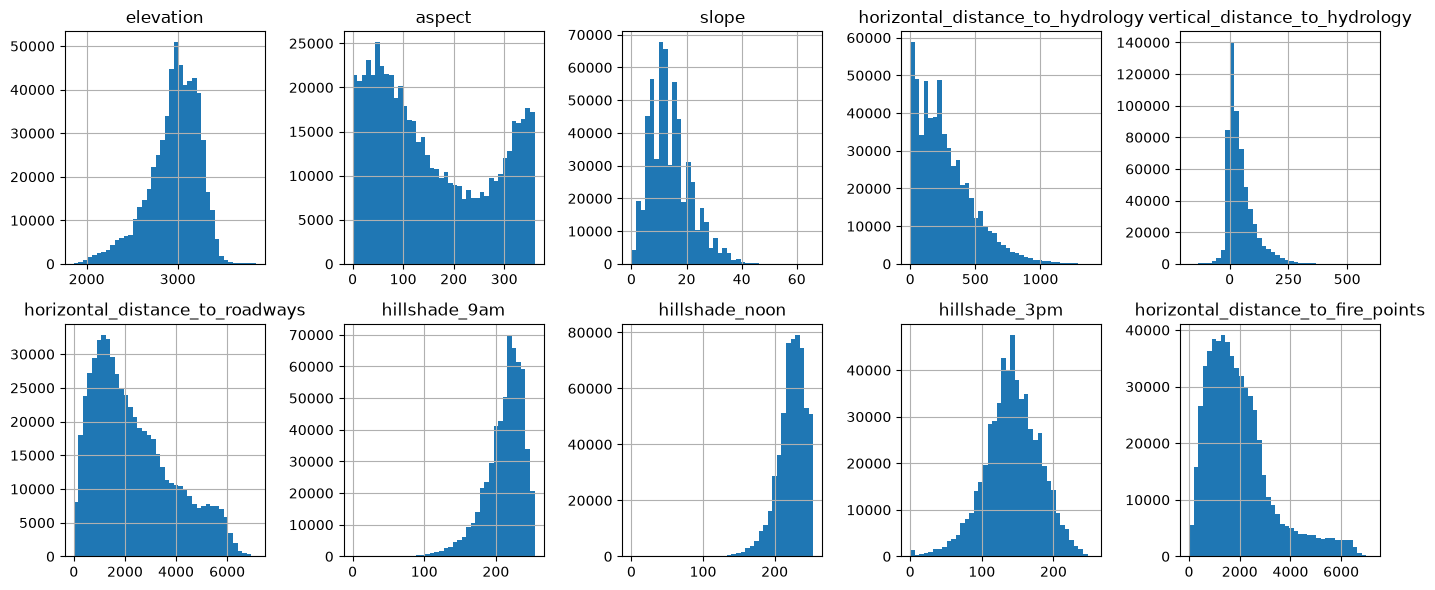

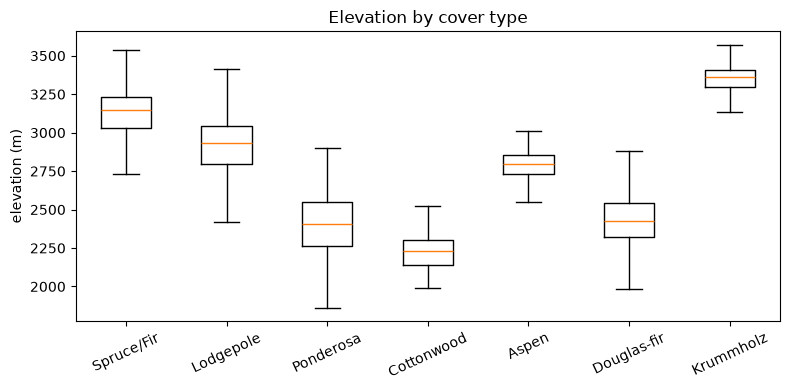

Mean of continuous features by class:
Cover_Type                           Aspen  Cottonwood  Douglas-fir  Krummholz  Lodgepole  Ponderosa  Spruce/Fir
elevation                           2787.0      2224.0       2419.0     3362.0     2921.0     2395.0      3129.0
aspect                               139.0       137.0        181.0      153.0      152.0      176.0       156.0
slope                                 17.0        19.0         19.0       14.0       14.0       21.0        13.0
horizontal_distance_to_hydrology     212.0       107.0        160.0      357.0      280.0      210.0       271.0
vertical_distance_to_hydrology        51.0        41.0         45.0       69.0       46.0       62.0        42.0
horizontal_distance_to_roadways     1350.0       914.0       1037.0     2738.0     2430.0      944.0      2615.0
hillshade_9am                        223.0       228.0        193.0      217.0      214.0      202.0       212.0
hillshade_noon                       219.0       217.0    

In [6]:
X[NUM_COLS].hist(bins=40, figsize=(14, 6), layout=(2, 5)); plt.tight_layout()
save_fig("eda_histograms"); plt.show()

# Elevation by class: the dominant feature
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([X.loc[y == k, "elevation"] for k in range(7)], showfliers=False)
ax.set_xticks(range(1, 8)); ax.set_xticklabels(SHORT_NAMES, rotation=25)
ax.set_ylabel("elevation (m)"); ax.set_title("Elevation by cover type")
plt.tight_layout(); save_fig("eda_elevation_by_class"); plt.show()

print("Mean of continuous features by class:")
print(X[NUM_COLS].groupby(y.map(dict(enumerate(SHORT_NAMES)))).mean().round(0).T.to_string())

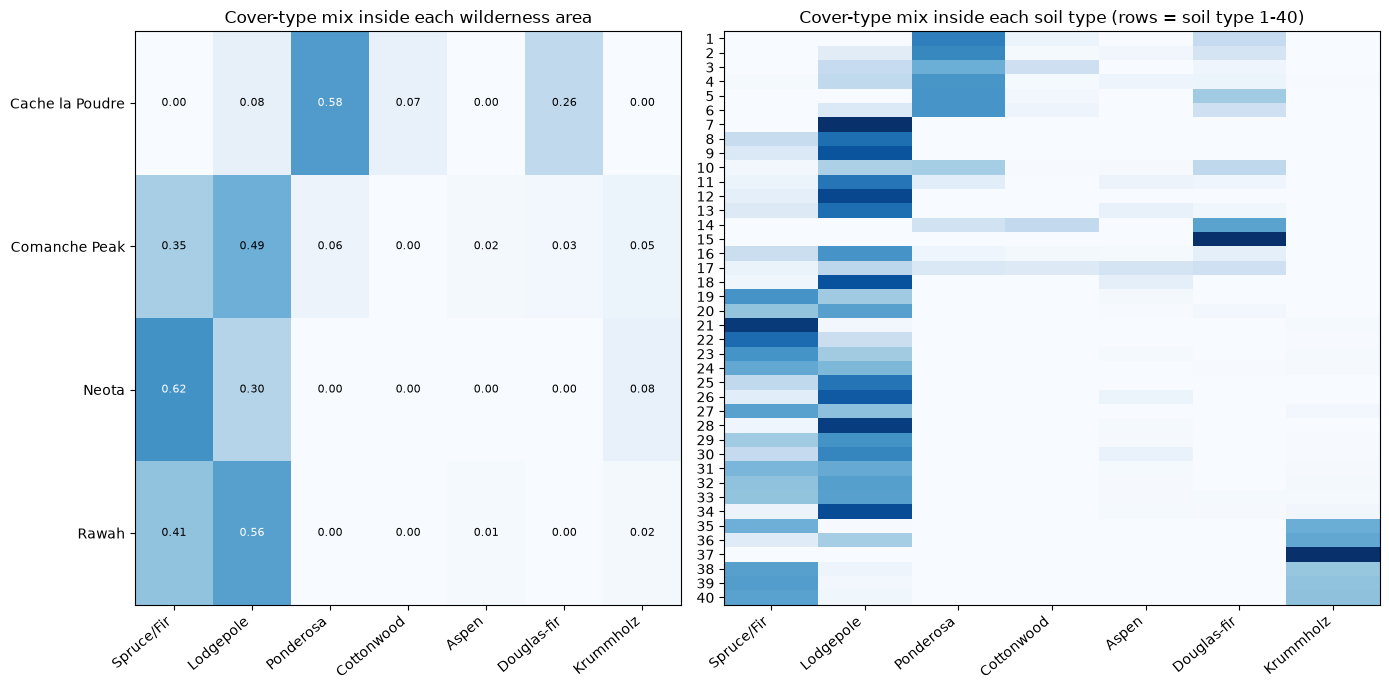

Rows per wilderness area:
 wilderness_area
Rawah              260796
Comanche Peak      253364
Cache la Poudre     36968
Neota               29884

Which areas does each cover type occur in? (share of that class)
wilderness_area  Cache la Poudre  Comanche Peak  Neota  Rawah
Cover_Type                                                   
Aspen                      0.000          0.602  0.000  0.398
Cottonwood                 1.000          0.000  0.000  0.000
Douglas-fir                0.561          0.439  0.000  0.000
Krummholz                  0.000          0.639  0.112  0.249
Lodgepole                  0.011          0.442  0.032  0.516
Ponderosa                  0.600          0.400  0.000  0.000
Spruce/Fir                 0.000          0.413  0.088  0.499


In [7]:
def heat(ax, table, title, annotate):
    im = ax.imshow(table.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(7)); ax.set_xticklabels(SHORT_NAMES, rotation=40, ha="right")
    ax.set_yticks(range(len(table))); ax.set_yticklabels(table.index)
    if annotate:
        for i in range(table.shape[0]):
            for j in range(table.shape[1]):
                ax.text(j, i, f"{table.values[i, j]:.2f}", ha="center", va="center",
                        color="white" if table.values[i, j] > 0.5 else "black", fontsize=8)
    return im

# Share of each area / soil type's rows belonging to each cover type
area_tab = pd.crosstab(area.map(AREA_NAMES), y, normalize="index").reindex(columns=range(7), fill_value=0)
soil_tab = pd.crosstab(soil, y, normalize="index").reindex(columns=range(7), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 1.2]})
heat(axes[0], area_tab, "Cover-type mix inside each wilderness area", annotate=True)
heat(axes[1], soil_tab, "Cover-type mix inside each soil type (rows = soil type 1-40)", annotate=False)
plt.tight_layout(); save_fig("eda_area_soil_heatmaps"); plt.show()

print("Rows per wilderness area:\n", area.map(AREA_NAMES).value_counts().to_string())
print("\nWhich areas does each cover type occur in? (share of that class)")
print(pd.crosstab(y.map(dict(enumerate(SHORT_NAMES))), area.map(AREA_NAMES), normalize="index").round(3).to_string())

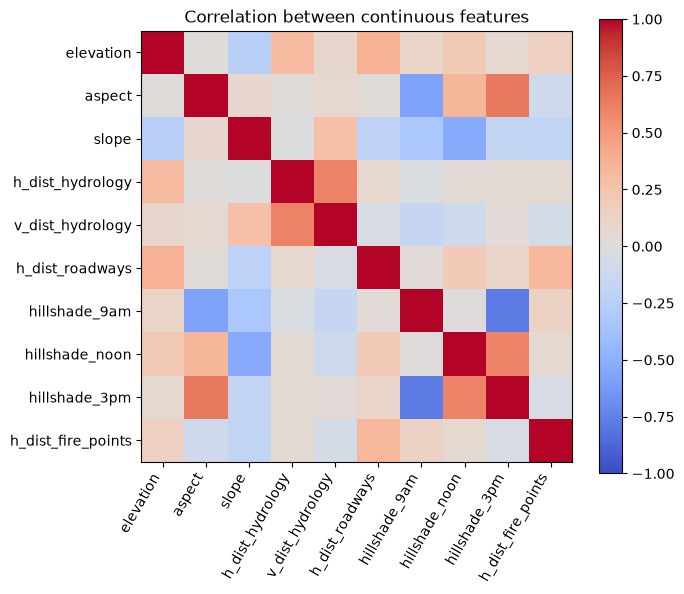

In [8]:
corr = X[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
short = [c.replace("horizontal_distance_to_", "h_dist_").replace("vertical_distance_to_", "v_dist_") for c in NUM_COLS]
ax.set_xticks(range(10)); ax.set_xticklabels(short, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(short)
plt.colorbar(im); ax.set_title("Correlation between continuous features")
plt.tight_layout(); save_fig("eda_correlation"); 
plt.show()

**My EDA notes** (fill in after running):
- Class balance and the majority-class accuracy: ...
- Data quality (missing, duplicates, constant columns, rare soil types): ...
- Strongest separating feature and how classes overlap: ...
- Wilderness area / soil type structure (are some cover types confined to one area?): ...
- Correlated features worth combining: ...

## 3. Feature engineering and splits

**Engineered features** are row-wise formulas with no fitted statistics, so computing them before the split cannot leak information. They target a weakness of trees (axis-aligned splits cannot express sums, differences or distances of columns cheaply) and follow well-known hydrology / roads / fire-point combinations for this dataset. Whether they help is decided by an ablation in Section 4, not assumed.

**Splits (stratified):** 80% train / 20% test. The training part is split again into **fit** (80%) and **validation** (20%). Models are compared and tuned on fit/validation. The **test set is used once**, for the final model only.

In [9]:
def add_engineered(Z):
    Z = Z.copy()
    h = Z["horizontal_distance_to_hydrology"]
    v = Z["vertical_distance_to_hydrology"]
    fire = Z["horizontal_distance_to_fire_points"]
    road = Z["horizontal_distance_to_roadways"]
    Z["dist_hydrology"] = np.sqrt(h ** 2 + v ** 2)
    Z["elev_minus_vdist_hydro"] = Z["elevation"] - v
    Z["elev_minus_hdist_hydro"] = Z["elevation"] - 0.2 * h
    Z["hydro_plus_fire"] = h + fire
    Z["hydro_minus_fire"] = h - fire
    Z["hydro_plus_road"] = h + road
    Z["hydro_minus_road"] = h - road
    Z["fire_plus_road"] = fire + road
    Z["fire_minus_road"] = fire - road
    Z["aspect_sin"] = np.sin(np.deg2rad(Z["aspect"]))
    Z["aspect_cos"] = np.cos(np.deg2rad(Z["aspect"]))
    new = [c for c in Z.columns if c not in X.columns]
    return Z.astype({c: "float32" for c in new})

X_all = add_engineered(X)
BASE_FEATURES = X.columns.tolist()
ENG_COLS = [c for c in X_all.columns if c not in X.columns]
print(f"{len(BASE_FEATURES)} original features + {len(ENG_COLS)} engineered: {ENG_COLS}")

# ---- Splits ----
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)

print(f"train {len(X_train):,} (fit {len(X_fit):,} + validation {len(X_val):,}) | test {len(X_test):,}")
print("Class shares   train:", (y_train.value_counts(normalize=True).sort_index().round(3).tolist()))
print("Class shares   test :", (y_test.value_counts(normalize=True).sort_index().round(3).tolist()))

def stratified_sample(Xd, yd, n):
    if n is None or n >= len(Xd):
        return Xd, yd
    Xs, _, ys, _ = train_test_split(Xd, yd, train_size=n, stratify=yd, random_state=RANDOM_STATE)
    return Xs, ys

54 original features + 11 engineered: ['dist_hydrology', 'elev_minus_vdist_hydro', 'elev_minus_hdist_hydro', 'hydro_plus_fire', 'hydro_minus_fire', 'hydro_plus_road', 'hydro_minus_road', 'fire_plus_road', 'fire_minus_road', 'aspect_sin', 'aspect_cos']
train 464,809 (fit 371,847 + validation 92,962) | test 116,203
Class shares   train: [0.365, 0.488, 0.062, 0.005, 0.016, 0.03, 0.035]
Class shares   test : [0.365, 0.488, 0.062, 0.005, 0.016, 0.03, 0.035]


## 4. Do engineered features earn their place? (ablation)

A Random Forest is trained on the same stratified subsample with (a) the original columns and (b) original + engineered columns, and scored on the **validation** set. Extra features are adopted only if they improve **macro-F1** by more than `MIN_GAIN`; otherwise the simpler original set is kept.

In [10]:
FEATURE_SETS = {"original columns": BASE_FEATURES,
                "original + engineered": BASE_FEATURES + ENG_COLS}

X_abl, y_abl = stratified_sample(X_fit, y_fit, ABL_N)
rows = []
for name, cols in FEATURE_SETS.items():
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=RF_TREES, n_jobs=N_JOBS, random_state=RANDOM_STATE)
    rf.fit(X_abl[cols], y_abl)
    pred = rf.predict(X_val[cols])
    rows.append({"feature_set": name, "n_features": len(cols),
                 "accuracy": accuracy_score(y_val, pred),
                 "macro_f1": f1_score(y_val, pred, average="macro"),
                 "fit_seconds": round(time.perf_counter() - t0, 1)})
ablation = pd.DataFrame(rows).set_index("feature_set")
ablation.round(4)

,n_features,accuracy,macro_f1,fit_seconds
feature_set,,,,
original columns,54,0.9089,0.8496,10.5
original + engineered,65,0.9441,0.9001,5.4


In [11]:
MIN_GAIN = 0.003               # required macro-F1 improvement to justify extra features
FORCE_FEATURE_SET = None       # or a key of FEATURE_SETS to override the automatic choice

gain = ablation.loc["original + engineered", "macro_f1"] - ablation.loc["original columns", "macro_f1"]
auto_choice = "original + engineered" if gain > MIN_GAIN else "original columns"
FEATURE_SET = FORCE_FEATURE_SET or auto_choice
FEATURES = FEATURE_SETS[FEATURE_SET]
CONT_COLS = [c for c in FEATURES if c not in WILD_COLS + SOIL_COLS]

print(f"Macro-F1 gain from engineered features: {gain:+.4f} (threshold {MIN_GAIN})")
print(f">>> Selected feature set: '{FEATURE_SET}' ({len(FEATURES)} features)")

Macro-F1 gain from engineered features: +0.0504 (threshold 0.003)
>>> Selected feature set: 'original + engineered' (65 features)


**Read the ablation:** if the engineered features help, say which kind of structure they expose (distances, differences between distance columns, elevation adjusted for water). If they do not help at this subsample size, say so. A feature that does not pay for itself is not kept.

## 5. Model comparison (fit on the fit set, scored on the validation set)

| Model | Why it is here |
|---|---|
| Dummy (majority) | reality check: accuracy equals the largest class share, macro-F1 near zero |
| Logistic Regression | linear baseline (scaled continuous features) on a subsample, because lbfgs on 0.4 M rows is slow |
| Decision Tree | single unpruned tree, to show what ensembling adds |
| Random Forest | bagged trees (bonus comparison) |
| Random Forest, balanced | `class_weight="balanced_subsample"`: does it lift the rare classes? |
| XGBoost | gradient-boosted trees (bonus comparison) |

Metrics: accuracy, **macro-F1** (classes weighted equally), weighted-F1 and fit time.

In [ ]:
RF_BASE  = dict(n_estimators=RF_TREES, n_jobs=N_JOBS, random_state=RANDOM_STATE)
XGB_BASE = dict(n_estimators=XGB_ROUNDS, max_depth=10, learning_rate=0.2, subsample=0.8, colsample_bytree=0.8,
                tree_method="hist", n_jobs=N_JOBS, random_state=RANDOM_STATE)

def make_lr():
    prep = ColumnTransformer([("scale", StandardScaler(), CONT_COLS)], remainder="passthrough")
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=300, random_state=RANDOM_STATE))])

FACTORIES = {   # name -> (factory, training rows or None for all fit rows)
    "Dummy (majority)":      (lambda: DummyClassifier(strategy="most_frequent"), None),
    "LogReg (subsample)":    (make_lr, LR_N),
    "Decision Tree":         (lambda: DecisionTreeClassifier(random_state=RANDOM_STATE), None),
    "Random Forest":         (lambda: RandomForestClassifier(**RF_BASE), None),
    "Random Forest (balanced)": (lambda: RandomForestClassifier(**RF_BASE, class_weight="balanced_subsample"), None),
    "XGBoost":               (lambda: XGBClassifier(**XGB_BASE), None),
}

val_rows = []
def run_on_validation(name, make, n_train):
    Xt, yt = stratified_sample(X_fit[FEATURES], y_fit, n_train)
    model = make()
    t0 = time.perf_counter()
    model.fit(Xt, yt)
    fit_s = time.perf_counter() - t0
    pred = model.predict(X_val[FEATURES])
    val_rows.append({"model": name, "train_rows": len(Xt),
                     "accuracy": accuracy_score(y_val, pred),
                     "macro_f1": f1_score(y_val, pred, average="macro"),
                     "weighted_f1": f1_score(y_val, pred, average="weighted"),
                     "fit_seconds": round(fit_s, 1)})
    print(f"{name:28s} acc={val_rows[-1]['accuracy']:.4f}  macro-F1={val_rows[-1]['macro_f1']:.4f}  ({fit_s:.0f}s)")

for name, (make, n_train) in FACTORIES.items():
    run_on_validation(name, make, n_train)

val_table = pd.DataFrame(val_rows).set_index("model").sort_values("macro_f1", ascending=False)
val_table.round(4)

Dummy (majority)             acc=0.4876  macro-F1=0.0936  (0s)
LogReg (subsample)           acc=0.7236  macro-F1=0.5330  (11s)


**Read the table:**
- How far does the linear model fall behind the tree models, and what does that say about the structure of the problem?
- Random Forest vs XGBoost: which is more accurate, which is faster, and is the macro-F1 gap bigger than the accuracy gap (a sign that the rare classes behave differently)?
- Does `class_weight="balanced_subsample"` help the rare classes, or does it just trade precision for recall?

## 6. Hyperparameter tuning (bonus)

`RandomizedSearchCV` explores each model on a stratified **subsample** (3-fold, optimising macro-F1), because searching on all 0.4 M rows is far too slow. The best settings are then **refitted on the full fit set** and compared on the same validation set as before. One caveat to keep in mind: settings chosen on a subsample can under-estimate how much capacity the full data supports (more trees, deeper trees).

In [ ]:
X_tune, y_tune = stratified_sample(X_fit[FEATURES], y_fit, TUNE_N)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_space = {"n_estimators": [100, 150, 200], "max_depth": [None, 30, 40],
            "min_samples_leaf": [1, 2, 3], "max_features": ["sqrt", 0.2, 0.3]}
xgb_space = {"n_estimators": [200, 300, 400], "max_depth": [6, 8, 10, 12],
             "learning_rate": [0.1, 0.2, 0.3], "subsample": [0.7, 0.85, 1.0],
             "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5]}

searches = {}
for name, est, space in [("Random Forest", RandomForestClassifier(n_jobs=N_JOBS, random_state=RANDOM_STATE), rf_space),
                         ("XGBoost", XGBClassifier(tree_method="hist", n_jobs=N_JOBS, random_state=RANDOM_STATE), xgb_space)]:
    t0 = time.perf_counter()
    rs = RandomizedSearchCV(est, space, n_iter=N_ITER, scoring="f1_macro", cv=cv3,
                            random_state=RANDOM_STATE, n_jobs=1, refit=False)
    rs.fit(X_tune, y_tune)
    searches[name] = rs
    print(f"{name}: best CV macro-F1 on the {len(X_tune):,}-row subsample = {rs.best_score_:.4f} "
          f"({time.perf_counter() - t0:.0f}s)\n   best params: {rs.best_params_}")

search_results = pd.concat([
    pd.DataFrame(rs.cv_results_).assign(model=name)[["model", "mean_test_score", "params"]]
    for name, rs in searches.items()]).sort_values(["model", "mean_test_score"], ascending=[True, False])
search_results.round(4).head(12)

In [ ]:
tuned_rf_params  = searches["Random Forest"].best_params_
tuned_xgb_params = searches["XGBoost"].best_params_

FACTORIES["Random Forest (tuned)"] = (lambda: RandomForestClassifier(**{**RF_BASE, **tuned_rf_params}), None)
FACTORIES["XGBoost (tuned)"] = (lambda: XGBClassifier(**{**XGB_BASE, **tuned_xgb_params}), None)

for name in ["Random Forest (tuned)", "XGBoost (tuned)"]:
    make, n_train = FACTORIES[name]
    run_on_validation(name, make, n_train)

val_table = pd.DataFrame(val_rows).set_index("model").sort_values("macro_f1", ascending=False)
val_table.round(4)

In [ ]:
# Final choice: best full-data tree model by validation macro-F1
eligible = [n for n in val_table.index if n in FACTORIES and FACTORIES[n][1] is None
            and n not in ("Dummy (majority)",)]
best_name = val_table.loc[eligible, "macro_f1"].idxmax()
print(f">>> Selected model: {best_name}  (validation macro-F1 {val_table.loc[best_name, 'macro_f1']:.4f}, "
      f"accuracy {val_table.loc[best_name, 'accuracy']:.4f})")

## 7. Final evaluation on the held-out test set

The selected model is refitted on **all training rows** (fit + validation) and scored on the test set **once**. The report shows per-class precision, recall and F1, because overall accuracy hides how the rare classes behave. The confusion matrix is shown as counts and **row-normalised** (each row sums to 1, so the diagonal is per-class recall).

In [ ]:
final_model = FACTORIES[best_name][0]()
t0 = time.perf_counter()
final_model.fit(X_train[FEATURES], y_train)
print(f"Refit on {len(X_train):,} rows in {time.perf_counter() - t0:.0f}s")

pred = final_model.predict(X_test[FEATURES])
test_acc = accuracy_score(y_test, pred)
test_macro = f1_score(y_test, pred, average="macro")
test_weighted = f1_score(y_test, pred, average="weighted")
print(f"\nTEST  accuracy={test_acc:.4f} | macro-F1={test_macro:.4f} | weighted-F1={test_weighted:.4f}\n")
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=SHORT_NAMES, cmap="Blues", values_format="d", ax=axes[0], colorbar=False)
axes[0].set_title(f"{best_name}: confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=SHORT_NAMES, cmap="Blues", normalize="true", values_format=".2f", ax=axes[1], colorbar=False)
axes[1].set_title("Row-normalised (diagonal = recall per class)")
for ax in axes:
    ax.set_xticklabels(SHORT_NAMES, rotation=40, ha="right")
plt.tight_layout(); save_fig("confusion_matrix_test"); plt.show()

# Which mistakes are most common?
cm = confusion_matrix(y_test, pred)
off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), cm[i, j] / cm[i].sum())
       for i in range(7) for j in range(7) if i != j]
top_confusions = pd.DataFrame(off, columns=["true class", "predicted as", "count", "share of true class"]) \
                   .sort_values("count", ascending=False).head(8)
top_confusions["share of true class"] = top_confusions["share of true class"].round(4)
print("Most common confusions:")
print(top_confusions.to_string(index=False))

In [ ]:
p, r, f, s = precision_recall_fscore_support(y_test, pred, labels=range(7), zero_division=0)
per_class = pd.DataFrame({"class": CLASS_NAMES, "precision": p, "recall": r, "f1": f, "support": s, "share_of_test": s / s.sum()}).set_index("class").round(4)

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(7)
ax.bar(x - 0.2, per_class["f1"], 0.4, label="F1", color="#4C72B0")
ax.bar(x + 0.2, per_class["share_of_test"], 0.4, label="share of test set", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(SHORT_NAMES, rotation=25); ax.set_ylim(0, 1.05)
ax.set_title("Per-class F1 vs how common the class is"); ax.legend()
plt.tight_layout(); save_fig("per_class_f1"); plt.show()
per_class

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy(); p_arr = np.asarray(pred)
boot = np.array([[accuracy_score(y_arr[i], p_arr[i]), f1_score(y_arr[i], p_arr[i], average="macro")]
                 for i in (rng.integers(0, len(y_arr), len(y_arr)) for _ in range(300))])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
print(f"Test accuracy : {test_acc:.4f}  (95% bootstrap CI {lo[0]:.4f} to {hi[0]:.4f})")
print(f"Test macro-F1 : {test_macro:.4f}  (95% bootstrap CI {lo[1]:.4f} to {hi[1]:.4f})")
print("Tuned RF params :", tuned_rf_params)
print("Tuned XGB params:", tuned_xgb_params)

## 8. Feature importance

Two views of the final model:
1. **Built-in importance** (split gain / impurity), with the 40 soil indicators and 4 wilderness indicators **summed into one group each**, because the one-hot encoding would otherwise split one idea into 44 tiny bars.
2. **Grouped permutation importance** on a test subsample: shuffle a feature (or a whole group, jointly, so one-hot rows stay valid) and measure the drop in macro-F1. This measures what the model actually needs, and is less biased than built-in importance.

In [ ]:
def group_of(c):
    if c.startswith("soil_type"):
        return "soil_type (all indicators)"
    if c.startswith("wilderness_area"):
        return "wilderness_area (all indicators)"
    return c

builtin = (pd.Series(final_model.feature_importances_, index=FEATURES)
             .groupby(group_of).sum().sort_values(ascending=False))

groups = {}
for c in FEATURES:
    groups.setdefault(group_of(c), []).append(c)

def grouped_permutation(model, Xs, ys, groups, n_repeats=3, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = f1_score(ys, model.predict(Xs), average="macro")
    drops = {}
    for g, cols in groups.items():
        d = []
        for _ in range(n_repeats):
            Xp = Xs.copy()
            perm = rng.permutation(len(Xs))
            Xp[cols] = Xs[cols].to_numpy()[perm]      # same row permutation for all columns of the group
            d.append(base - f1_score(ys, model.predict(Xp), average="macro"))
        drops[g] = float(np.mean(d))
    return pd.Series(drops).sort_values(ascending=False), base

X_perm = X_test[FEATURES].sample(min(PERM_N, len(X_test)), random_state=RANDOM_STATE)
y_perm = y_test.loc[X_perm.index]
perm_imp, perm_base = grouped_permutation(final_model, X_perm, y_perm, groups)
print(f"Baseline macro-F1 on the permutation sample: {perm_base:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
builtin.head(15)[::-1].plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Built-in importance (grouped), top 15")
perm_imp.head(15)[::-1].plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Grouped permutation importance (drop in macro-F1), top 15")
plt.tight_layout(); save_fig("feature_importance"); plt.show()

pd.DataFrame({"built_in": builtin.round(4), "permutation_drop": perm_imp.round(4)}).sort_values(
    "permutation_drop", ascending=False).head(12)

## 9. Learning curve: how much does more data help?

A Random Forest (a cheaper stand-in for the final model) is trained on growing fractions of the fit set and scored on the validation set. A curve that is still rising at full size means the model is **data-hungry**, which is typical for this dataset.

In [ ]:
sizes = sorted({min(s, len(X_fit)) for s in
                ([2_000, 5_000, 10_000, 20_000] if FAST_MODE else [5_000, 20_000, 50_000, 100_000, 200_000]) + [len(X_fit)]})
lc_rows = []
for n in sizes:
    Xs, ys = stratified_sample(X_fit[FEATURES], y_fit, n)
    rf = RandomForestClassifier(n_estimators=max(RF_TREES // 2, 20), n_jobs=N_JOBS, random_state=RANDOM_STATE).fit(Xs, ys)
    pr = rf.predict(X_val[FEATURES])
    lc_rows.append({"train_rows": len(Xs), "accuracy": accuracy_score(y_val, pr),
                    "macro_f1": f1_score(y_val, pr, average="macro")})
    print(f"{len(Xs):>8,} rows: accuracy={lc_rows[-1]['accuracy']:.4f}  macro-F1={lc_rows[-1]['macro_f1']:.4f}")
learning_curve = pd.DataFrame(lc_rows).set_index("train_rows")

fig, ax = plt.subplots(figsize=(6.5, 4))
learning_curve.plot(marker="o", ax=ax); ax.set_xscale("log"); ax.grid(alpha=0.3)
ax.set_title("Validation score vs training-set size (Random Forest)"); ax.set_ylabel("score")
plt.tight_layout(); save_fig("learning_curve"); plt.show()

## 10. Stress test: does it generalise to an unseen area?

Neighbouring 30 m cells look alike, so a **random** split lets the model "see" a nearby twin of every test cell. This test is harsher and closer to real use: train on **three wilderness areas** and test on the **fourth, completely unseen area** (leave-one-area-out). Only training-split rows are used, so the real test set stays untouched.

Read it with care: some cover types occur in only one area, so when that area is held out the model has *never seen* the class and cannot predict it. Part of any drop is therefore unavoidable, and the table lists which classes were unseen.

In [ ]:
area_train = area.loc[X_train.index]
spatial_rows = []
for a, a_name in AREA_NAMES.items():
    held = area_train == a
    if held.sum() == 0:
        continue
    X_tr, y_tr = stratified_sample(X_train.loc[~held, FEATURES], y_train.loc[~held], SPATIAL_N)
    X_ho, y_ho = X_train.loc[held, FEATURES], y_train.loc[held]
    rf = RandomForestClassifier(n_estimators=max(RF_TREES // 2, 20), n_jobs=N_JOBS, random_state=RANDOM_STATE).fit(X_tr, y_tr)
    pr = rf.predict(X_ho)
    present = np.unique(y_ho)
    unseen = sorted(set(present) - set(np.unique(y_tr)))
    spatial_rows.append({"held-out area": a_name, "rows": int(held.sum()),
                         "classes in area": ", ".join(SHORT_NAMES[k] for k in present),
                         "unseen in training": ", ".join(SHORT_NAMES[k] for k in unseen) or "none",
                         "accuracy": accuracy_score(y_ho, pr),
                         "macro_f1 (classes present)": f1_score(y_ho, pr, labels=present, average="macro", zero_division=0)})

spatial = pd.DataFrame(spatial_rows).set_index("held-out area")
rand_ref = val_table.loc["Random Forest", ["accuracy", "macro_f1"]] if "Random Forest" in val_table.index else None
print("Reference, same model family with a RANDOM split: accuracy = "
      f"{rand_ref['accuracy']:.4f}, macro-F1 = {rand_ref['macro_f1']:.4f}\n")
spatial.round(4)

In [ ]:
def leave_one_area_out(features, label):
    rows = []
    for a, a_name in AREA_NAMES.items():
        held = area_train == a
        if held.sum() == 0:
            continue
        X_tr, y_tr = stratified_sample(X_train.loc[~held, features], y_train.loc[~held], SPATIAL_N)
        X_ho, y_ho = X_train.loc[held, features], y_train.loc[held]
        rf = RandomForestClassifier(n_estimators=max(RF_TREES // 2, 20), n_jobs=N_JOBS,
                                    random_state=RANDOM_STATE).fit(X_tr, y_tr)
        pr = rf.predict(X_ho)
        present = np.unique(y_ho)
        rows.append({"features": label, "held-out area": a_name,
                     "accuracy": accuracy_score(y_ho, pr),
                     "macro_f1 (classes present)": f1_score(y_ho, pr, labels=present, average="macro", zero_division=0)})
    return pd.DataFrame(rows)

no_area = [c for c in FEATURES if c not in WILD_COLS]
spatial_cmp = pd.concat([leave_one_area_out(FEATURES, "all features"),
                         leave_one_area_out(no_area, "no area indicators"),
                         leave_one_area_out(CONT_COLS, "continuous only")])
spatial_cmp_table = spatial_cmp.pivot(index="held-out area", columns="features",
                                      values=["accuracy", "macro_f1 (classes present)"]).round(4)
spatial_cmp_table.to_csv(RES_DIR / "spatial_stress_test_variants.csv")
spatial_cmp_table

In [ ]:
spatial_fe = leave_one_area_out(BASE_FEATURES, "original features")
cmp_fe = spatial_fe.set_index("held-out area")[["accuracy", "macro_f1 (classes present)"]].join(
    spatial_cmp[spatial_cmp["features"] == "all features"].set_index("held-out area")[
        ["accuracy", "macro_f1 (classes present)"]], lsuffix=" (original)", rsuffix=" (engineered)")
cmp_fe.round(4)

**Read the table:** compare each held-out accuracy with the random-split reference. The gap is the optimism built into the standard random split, and the reason a model trained on this forest should not be trusted on a different one without re-validation.

## 11. Save results

Everything the README needs is written to `results/`, and the final model is saved to `models/`. The model file can be large (forests are big), so keep `models/` out of Git.

In [ ]:
val_table.round(4).to_csv(RES_DIR / "validation_comparison.csv")
ablation.round(4).to_csv(RES_DIR / "feature_ablation.csv")
per_class.to_csv(RES_DIR / "test_per_class.csv")
top_confusions.to_csv(RES_DIR / "top_confusions.csv", index=False)
pd.DataFrame({"built_in": builtin, "permutation_drop": perm_imp}).round(5).to_csv(RES_DIR / "feature_importance.csv")
learning_curve.round(4).to_csv(RES_DIR / "learning_curve.csv")
spatial.round(4).to_csv(RES_DIR / "spatial_stress_test.csv")
pd.DataFrame([{"model": best_name, "feature_set": FEATURE_SET, "n_features": len(FEATURES),
               "test_accuracy": test_acc, "test_macro_f1": test_macro, "test_weighted_f1": test_weighted,
               "train_rows": len(X_train), "test_rows": len(X_test), "fast_mode": FAST_MODE}]).round(4).to_csv(
    RES_DIR / "test_summary.csv", index=False)

if SAVE_MODEL:
    joblib.dump({"model": final_model, "features": FEATURES, "class_names": CLASS_NAMES},
                MODEL_DIR / "forest_cover_model.joblib", compress=3)
    print("Model file:", round((MODEL_DIR / "forest_cover_model.joblib").stat().st_size / 1e6, 1), "MB")
print("Tables :", sorted(p.name for p in RES_DIR.iterdir()))
print("Figures:", sorted(p.name for p in IMG_DIR.iterdir()))

## 12. Conclusions and limitations (write your own version)

**Dataset:** 581,012 cells, 7 cover types, strongly imbalanced (majority class ... %, smallest ... %). Selected feature set: ... (ablation gain ...).

**Best model:** ... with test accuracy ... and macro-F1 ... (majority-class baseline accuracy: ...).

**Random Forest vs XGBoost:** ... (accuracy, macro-F1, fit time). Tuning changed validation macro-F1 from ... to ....

**Per-class behaviour:** easiest class ..., hardest class ... (F1 ...). The most common mistake is ... confused with ..., which makes sense because ... (similar elevation band).

**What drives predictions:** ... (elevation, then ...). Soil type as a group ranks ....

**Learning curve:** still rising at full size / flattening at ... rows.

**Limitations**
- **Spatial autocorrelation:** random splits are optimistic. In the leave-one-area-out test, accuracy fell to ... on the hardest area, and some cover types never appear outside one area.
- One region only (Roosevelt National Forest, Colorado): the model learns this forest, not forests in general.
- Cartographic variables only: no satellite imagery, so classes that differ in canopy rather than terrain stay hard to separate.
- Hyperparameters were searched on a subsample with only a few candidates; a larger search could improve the results slightly.
- Probabilities were not calibrated, and no cost-sensitive decision rule was used for the rare classes.

**Next steps:** spatially blocked cross-validation, LightGBM / CatBoost comparison, calibrated probabilities, class-specific thresholds for the rare classes.